# 13 — Sessão 2: ingestão, ACL e memória

Exercício executável do **contrato local** de um indexador comum. Não
chama SharePoint, BDA, OpenSearch, Bedrock Knowledge Bases ou Memory AWS.
O objetivo é demonstrar o que cada conector precisa preservar antes de
conectarmos os serviços reais. Veja a [agenda e dependências](../docs/ingestao/sessao-2.md).

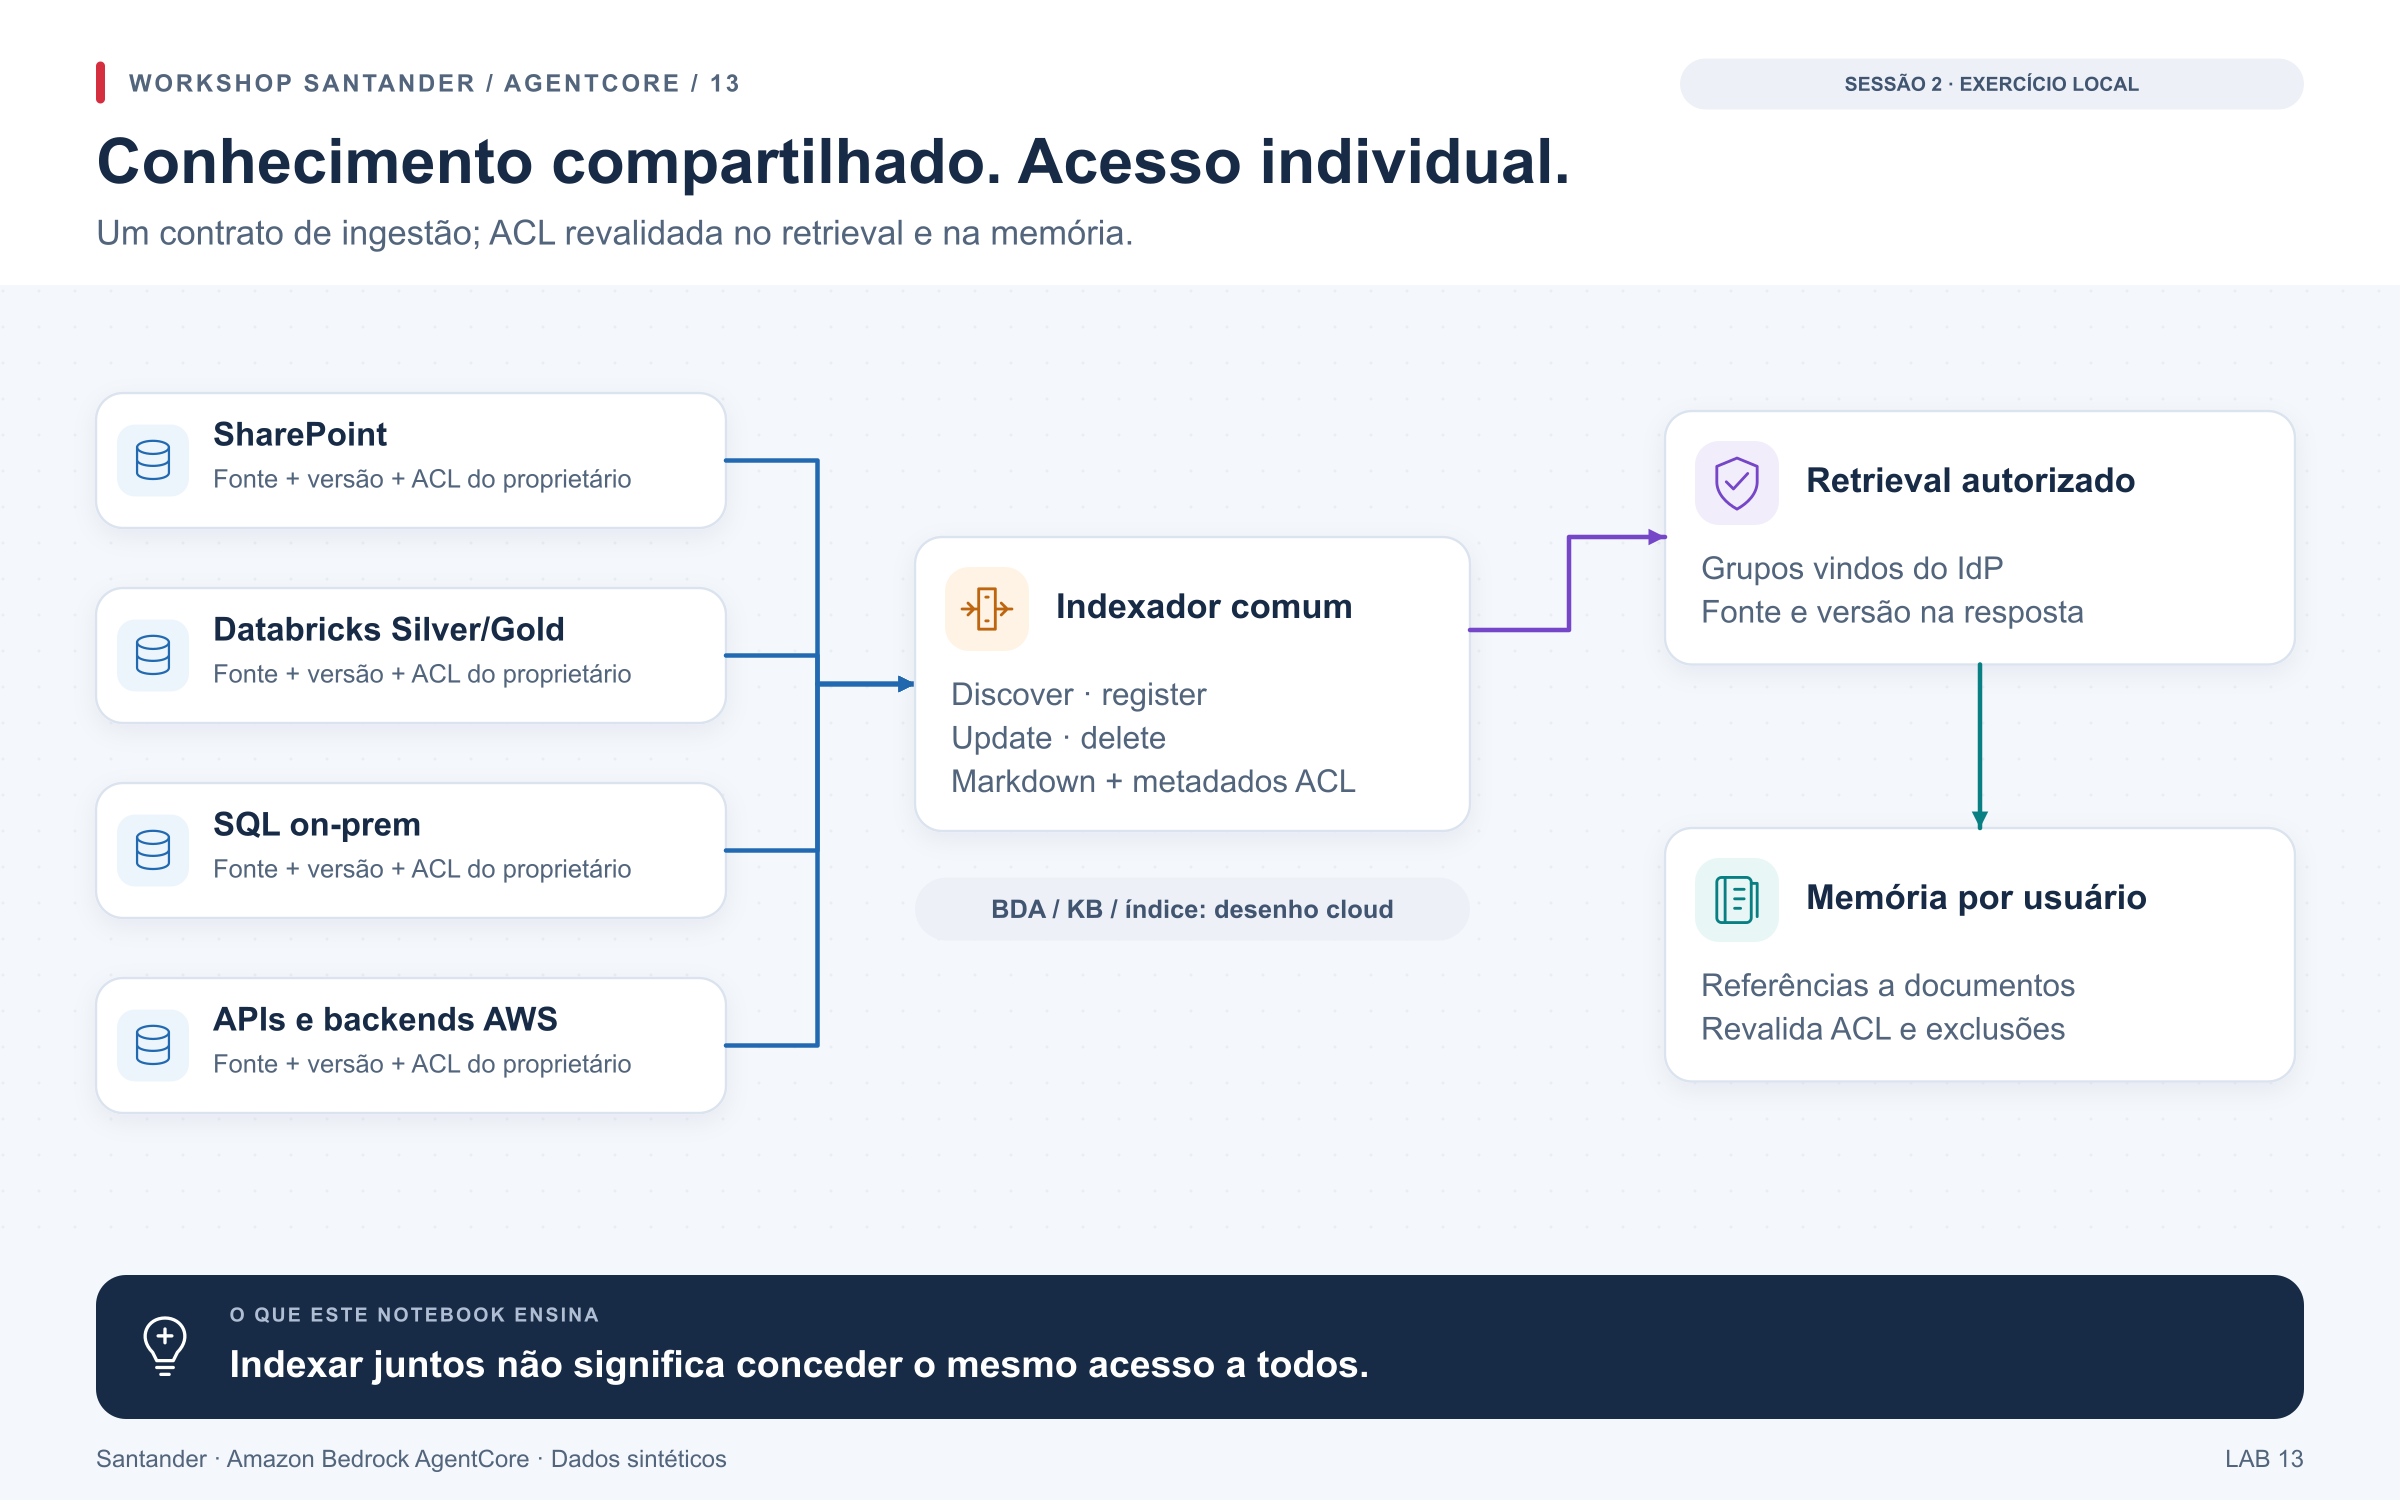

[Ampliar imagem](../docs/ingestao/arquitetura.png)

## 1. Contratos de fonte

A célula lista as quatro origens do HTML. O conteúdo de exercício é
Markdown sintético, representando a saída normalizada de um conector/BDA.
Nenhuma credencial de fonte é necessária.

In [ ]:
import json
from pathlib import Path
from IPython.display import display
from santander_demo.knowledge import KnowledgeLab, local_knowledge_demo
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sources = KnowledgeLab().discover()
display(sources)

## 2. Register → retrieve → update de ACL → delete

Dois documentos compartilham o mesmo índice, mas usuários Riscos e Fraude
enxergam conjuntos diferentes. O usuário Ambos vê os dois. O exercício
grava referências na memória, troca a ACL e verifica que a referência
antiga deixa de revelar o documento. Reusar o mesmo ID de sessão com
outro usuário também não dá acesso à memória.

A célula executa as operações e suas asserções. `version` e hash permitem
detectar atualizações; exclusão elimina o documento do retrieval.

In [ ]:
knowledge_report = local_knowledge_demo()
display(knowledge_report)
assert knowledge_report["visibility_before"]["user-riscos"] == ["R1"]
assert knowledge_report["visibility_before"]["user-fraude"] == ["F1"]
assert knowledge_report["revoked_acl_in_memory"] == "DENIED"
target = ROOT / "evidence/ingestao-local.json"
target.write_text(json.dumps(knowledge_report, ensure_ascii=False, indent=2) + "\n")

## 3. Traduzir o contrato para os serviços

Os grupos precisam vir de identidade verificada; o LLM não pode escolher
ACL ou `user_id`. Na KB/OpenSearch, aplicar filtros no backend e impedir
acesso direto à role de serviço. Mudanças de ACL e exclusões precisam
invalidar índice, caches e memória. Unity Catalog continua sendo a
autoridade dos dados Databricks.

BDA normaliza conteúdo; não concede acesso. Agent Registry cataloga
capacidades; não substitui D2K. “AWS Context” e Neptune ficam como itens
de confirmação de produto/necessidade, sem status comercial inferido.

O próximo ensaio real é um conector escolhido, dois usuários, uma revogação
e uma exclusão, pelo pipeline IaC do proprietário.

## Cleanup — recursos do laboratório

O notebook 12 possui um ambiente próprio em três contas. Remova, nesta ordem:

1. `origin-bindings` na origem.
2. `riscos-agent` e `fraude-agent` na origem.
3. `registry` na plataforma e `platform-bindings` na plataforma.
4. `data-bindings` no domínio de dados.
5. Os três stacks `*-gateway`, cada um em sua conta.
6. `bootstrap` em cada conta, após revisar os buckets retidos.

Use o nome real e o ARN revisado de cada stack. O wrapper não remove os
aplicativos Entra, a federation Databricks, tabelas, grants ou segredos
externos. Esses recursos pertencem ao IaC dos seus proprietários.
O notebook 13 é um exercício local; não cria recursos cloud.
Consulte o [runbook integrado](../docs/journey/README.md).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "journey",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Cleanup — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['APPLY_CHANGESET', 'CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET',
 'CONFIG_PATH', 'DEPLOY_PHASE', 'LIVE', 'MODE', 'RUN_AGENT', 'RUN_AWS', 'RUN_PIPELINE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'cloud', 'config', 'environment', 'identity', 'knowledge_report',
 'lab', 'sessions', 'source', 'sources', 'target', 'token', 'user_token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json